In [ ]:
import os
import scipy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import font_manager as fm

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR
KANWISHER_LOCALIZER_DIR = paths.KANWISHER_LOCALIZER_DIR

Font name from TTC: Avenir
Style: Book


# % Category-selective units across Layers

In [49]:
from compcats.models import alexnet_imagenet1kv1, resnet50_imagenet1kv2, resnet50_openaiclip

# 'resnet50robustl2eps3': resnet50_robust, # Done
# 'resnet50sin': resnet50_sin, # Done
# 'resnet50ecoset': resnet50_ecoset, # Done
# 'resnet50faceobfuscation': resnet50_faceobfuscation, # Done
# 'resnet50toponettau30': resnet50_toponet, # Done
# 'resnet50cesslbarlowtop': resnet50_cessl, # Done
# 'resnet50blurstrong': resnet50_blur, # Done

model_names = [
    'resnet50imagenet1kv2', 'resnet50openaiclip', 'resnet50simclr', 'resnet50robustl2eps3',
    'resnet50sin', 'resnet50ecoset', 'resnet50faceobfuscation',
    'resnet50toponettau30', 'resnet50cesslbarlowtop', 'resnet50blurstrong',
]

tthreshold = 7
colors = cm.tab10.colors

models = [ma.get_model(name) for name in model_names]

frois = ['FFA', 'PPA', 'EBA']

/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


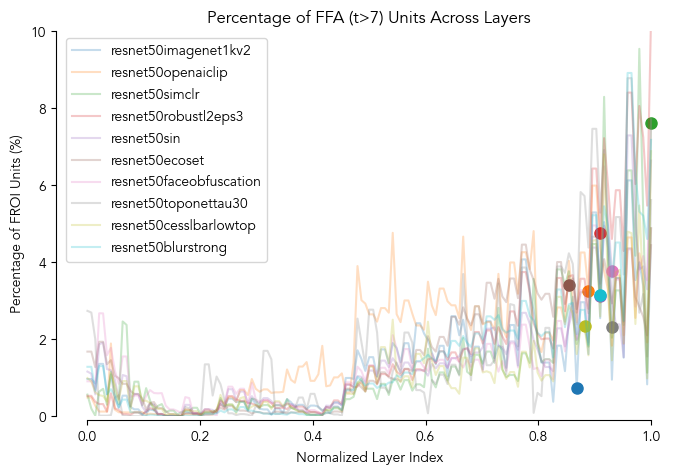

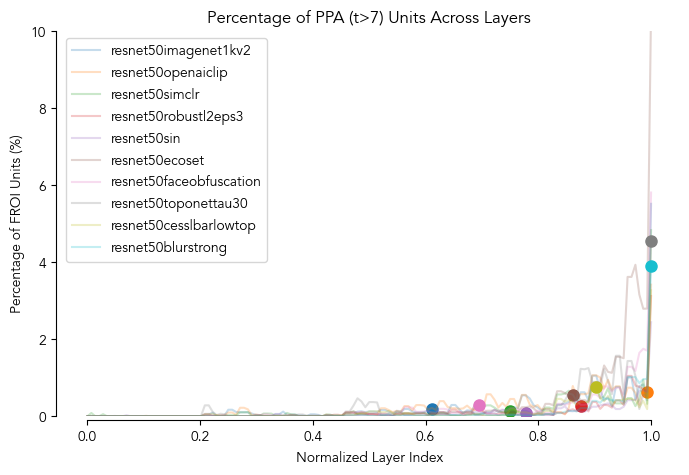

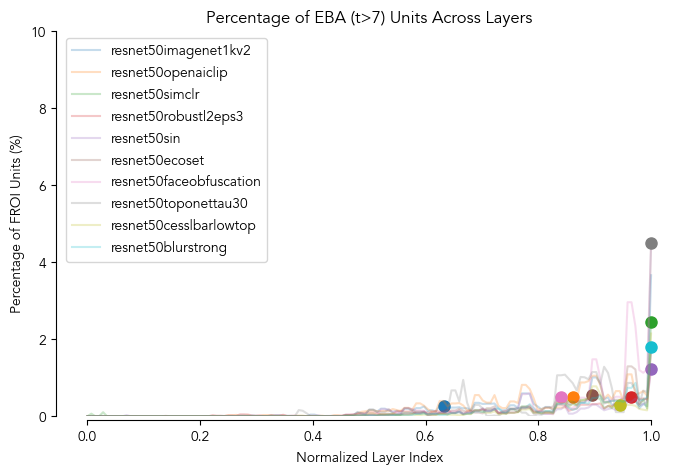

In [59]:
for froi in frois:
    froi_best_layers = ma.get_froi_models_layers(froi, froi)

    plt.figure(figsize=(8, 5))

    for model_idx, model in enumerate(models):
        model_layers = model.relevant_layer_names
        model_best_layer = froi_best_layers[model.name]
        # get index of the best layer for the model
        best_layer_idx = model_layers.index(model_best_layer)
        # plot_data = []

        model_layer_idxs = []
        model_percent_froi_units = []

        for layer_idx, layer in enumerate(model_layers):
            layer_froi_mask = localizer.get_froi_mask(
                GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
                model, layer, froi, tthreshold
            )
            n_units_froi = layer_froi_mask.sum()
            n_units_total = layer_froi_mask.numel()
            percent_froi_units = n_units_froi / n_units_total * 100
            # Append data for plotting
            model_layer_idxs.append(layer_idx)
            model_percent_froi_units.append(percent_froi_units.item())

        # Normalize the model_layer_idxs to [0, 1]
        model_layer_idxs_normalized = np.array(model_layer_idxs) / (len(model_layers) - 1)

        # plot_data.append({
        #     model.name: [model_layer_idxs_normalized, model_percent_froi_units]
        # }

        plt.plot(
            model_layer_idxs_normalized, model_percent_froi_units,
            '-', color=colors[model_idx], label=f'{model.name}', alpha=0.25
        )
        # Mark the best layer with a marker
        plt.plot(
            model_layer_idxs_normalized[best_layer_idx], model_percent_froi_units[best_layer_idx],
            'o', color=colors[model_idx], markersize=8, alpha=1
        )

    plt.ylim((0, 10))
    plt.legend()
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 2.5))
    plt.gca().spines['bottom'].set_position(('outward', 2.5))
    plt.gca().spines['bottom'].set_bounds(0, 1)
    plt.title(f'Percentage of {froi} (t>{tthreshold}) Units Across Layers')
    plt.xlabel('Normalized Layer Index')
    plt.ylabel('Percentage of FROI Units (%)')
    plt.show()